# SteelOps AI — Análise exploratória explicada

**Objetivo deste notebook:** entender os dados antes de qualquer modelo. Cada coluna, cada unidade, cada padrão e cada armadilha.

Este é um notebook de estudo, escrito em português. O código e os comentários estão em inglês, como no resto do projeto. Toda lógica de dados (carregar, corrigir, auditar) vem do pacote `steelops`, a mesma que o pipeline de modelagem vai usar. O notebook só explora e explica.

**Roteiro**

1. De onde vêm os dados
2. Primeiro contato com o arquivo
3. O que é cada coluna (com a física por trás)
4. Qualidade dos dados
5. A armadilha da meia-noite
6. Colunas que são cópias disfarçadas do alvo
7. Como a planta consome energia
8. O comportamento elétrico: reativos e fator de potência
9. O `Load_Type` e o calendário
10. Memória da série: autocorrelação
11. O que isso significa para a previsão
12. Limitações do dataset

> Convenção de leitura: **Observação** é o que os dados mostram. **Hipótese** é uma interpretação plausível que os dados não provam sozinhos.

In [1]:
import holidays
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots

from steelops.config import load_config
from steelops.data.audit import implied_power_factor, run_audit
from steelops.data.clean import load_clean
from steelops.data.load import load_raw, raw_csv_path, read_raw_frame
from steelops.visualization.theme import (
    CATEGORICAL,
    SEQUENTIAL_BLUE,
    TEXT_SECONDARY,
    register_template,
)

register_template()
# Interactive in Jupyter / VS Code, static PNG fallback for GitHub and HTML export.
pio.renderers.default = "plotly_mimetype+png"
pio.defaults.default_width = 1000
pio.defaults.default_height = 480
pio.defaults.default_scale = 1.5
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

config = load_config()

## 1. De onde vêm os dados

| Item | Valor |
|---|---|
| Nome | Steel Industry Energy Consumption |
| Fonte oficial usada | UCI Machine Learning Repository, dataset 851 |
| DOI | 10.24432/C52G8C |
| Licença | CC BY 4.0 (uso livre com atribuição) |
| Empresa | DAEWOO Steel Co. Ltd, Gwangyang, Coreia do Sul |
| O que a planta produz | bobinas, chapas de aço e chapas de ferro (segundo a UCI) |
| Período | 2018, um ano completo |
| Resolução | 15 minutos |
| Artigo de origem | Sathishkumar V E, Shin C., Cho Y. (2021). *Efficient energy consumption prediction model for a data analytic-enabled industry building in a smart city*. Building Research & Information, 49(1), 127–143 |

O mesmo arquivo foi publicado pelo autor no Mendeley Data (dez/2020) e no IEEE DataPort antes de chegar à UCI (doação em ago/2023). Também existem várias cópias no Kaggle. Por isso ele é tão conhecido.

**Como garantimos que o arquivo é o oficial:** o módulo `steelops.data.download` grava o zip e o CSV em `data/raw/`, calcula o SHA-256 de cada um, registra tudo em `data/raw/MANIFEST.json` e deixa os arquivos somente leitura. A camada *raw* nunca é alterada. Correções acontecem depois, em código, de forma explícita.

In [3]:
import json

manifest = json.loads((raw_csv_path(config).parent / "MANIFEST.json").read_text())
{
    k: manifest[k] for k in ["dataset", "doi", "license", "acquisition_method", "retrieved_at_utc"]
} | {"csv_sha256": manifest["files"]["csv"]["sha256"]}

{'dataset': 'Steel Industry Energy Consumption',
 'doi': '10.24432/C52G8C',
 'license': 'CC BY 4.0',
 'acquisition_method': 'download',
 'retrieved_at_utc': '2026-11-08T23:00:01+00:00',
 'csv_sha256': '9b1cee6f9cb9cd9df2b95814ca90a9a2ff15b7f5f1fba0fae3c643e82072eacc'}

## 2. Primeiro contato com o arquivo

Primeiro, o CSV exatamente como está no disco: tudo lido como texto, sem nenhuma interpretação do pandas. É a melhor forma de ver o arquivo "cru".

In [4]:
raw_text = read_raw_frame(raw_csv_path(config))
print(f"{raw_text.shape[0]:,} linhas x {raw_text.shape[1]} colunas")
raw_text.head(6)

35,040 linhas x 11 colunas


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0,0,73.21,100,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4,4.46,0,0,66.77,100,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0,0,70.28,100,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0,0,68.09,100,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.5,0,0,64.72,100,4500,Weekday,Monday,Light_Load
5,01/01/2018 01:30,3.28,3.56,0,0,67.76,100,5400,Weekday,Monday,Light_Load


Algumas coisas já aparecem nas primeiras linhas:

- A data está no formato **dia/mês/ano** (`01/01/2018 00:15`). Se o pandas adivinhasse o formato, `01/02/2018` poderia virar 2 de janeiro em vez de 1º de fevereiro. Por isso o projeto usa um formato explícito, definido em `configs/data.yaml`.
- O primeiro registro é **00:15**, não 00:00. Isso sugere que cada linha é rotulada pelo **fim** do intervalo de 15 minutos: a linha `00:15` mede o consumo entre 00:00 e 00:15.

Agora o final do arquivo:

In [5]:
raw_text.tail(4)

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
35036,31/12/2018 23:15,3.74,3.74,0,0,70.71,100,83700,Weekday,Monday,Light_Load
35037,31/12/2018 23:30,3.78,3.17,0.07,0,76.62,99.98,84600,Weekday,Monday,Light_Load
35038,31/12/2018 23:45,3.78,3.06,0.11,0,77.72,99.96,85500,Weekday,Monday,Light_Load
35039,31/12/2018 00:00,3.67,3.02,0.07,0,77.22,99.98,0,Weekday,Monday,Light_Load


A última linha é `31/12/2018 00:00` e vem **depois** de `31/12/2018 23:45`. Guarde isso. A seção 5 mostra que esse detalhe é uma armadilha.

Agora carregamos com os tipos corretos e nomes de coluna padronizados (`snake_case`). O mapeamento fica em `configs/data.yaml`:

In [6]:
df_raw = load_raw()  # typed, renamed, ORIGINAL file order, no corrections
pd.DataFrame(
    {
        "raw_name": list(config["schema"]["columns"].keys()),
        "canonical_name": list(config["schema"]["columns"].values()),
        "dtype": [str(df_raw[c].dtype) for c in config["schema"]["columns"].values()],
    }
)

,raw_name,canonical_name,dtype
0,date,timestamp,datetime64[us]
1,Usage_kWh,usage_kwh,float64
2,Lagging_Current_Reactive.Power_kVarh,lagging_reactive_kvarh,float64
3,Leading_Current_Reactive_Power_kVarh,leading_reactive_kvarh,float64
4,CO2(tCO2),co2_tco2,float64
5,Lagging_Current_Power_Factor,lagging_power_factor,float64
6,Leading_Current_Power_Factor,leading_power_factor,float64
7,NSM,nsm,int64
8,WeekStatus,week_status,string
9,Day_of_week,day_of_week,string


## 3. O que é cada coluna

Antes da tabela, dois conceitos que atravessam todas as colunas elétricas.

### Energia (kWh) não é potência (kW)

Pense num carro. A **potência** (kW) é o **velocímetro**: quanto está sendo consumido *naquele instante*. A **energia** (kWh) é o **hodômetro**: quanto foi acumulado *ao longo de um tempo*.

Cada linha do dataset é energia acumulada em 15 minutos. Para chegar à **potência média** no intervalo, multiplica-se por 4 (há quatro intervalos de 15 min em uma hora):

$$P_{\text{média}}\,[\text{kW}] = E_{15\text{min}}\,[\text{kWh}] \times 4$$

Exemplo: 73 kWh em 15 minutos correspondem a uma potência média de cerca de 292 kW nesse intervalo. Um pico instantâneo de potência pode ter sido maior, porque a média de 15 minutos suaviza os picos. **Por isso o dataset não permite falar em picos instantâneos de demanda**, só em médias de 15 minutos.

### Energia ativa, reativa e aparente: a analogia do chope

Num copo de chope, o **líquido** é o que mata a sede, a **espuma** ocupa espaço sem matar a sede, e o **copo inteiro** é o que você paga para transportar.

- **Energia ativa (kWh)** é o líquido. É ela que vira trabalho útil: girar motores, laminar, aquecer.
- **Energia reativa (kVArh)** é a espuma. Motores e transformadores precisam dela para criar campos magnéticos. Ela vai e volta entre a rede e o equipamento, sem virar trabalho, mas ocupa a capacidade dos cabos e transformadores.
- **Energia aparente (kVAh)** é o copo. É a soma vetorial das duas, e é para ela que a infraestrutura elétrica precisa ser dimensionada.

As três formam um triângulo retângulo, o **triângulo de potências**:

$$S = \sqrt{P^2 + Q^2} \qquad\qquad \text{FP} = \frac{P}{S}$$

O **fator de potência (FP)** é a fração "útil" do copo. FP = 100% significa um copo sem espuma.

### Reativo indutivo (*lagging*) e capacitivo (*leading*)

- **Lagging** (atrasado, ou **indutivo**): a corrente fica atrás da tensão. Acontece em cargas com bobinas, como motores, transformadores e fornos de indução. É o caso típico de uma indústria.
- **Leading** (adiantado, ou **capacitivo**): a corrente fica à frente da tensão. Acontece com capacitores. Indústrias instalam **bancos de capacitores** justamente para compensar o reativo indutivo e levar o FP para perto de 100%. Se o banco fica ligado quando os motores desligam, a planta passa a ter reativo capacitivo sobrando.

As concessionárias cobram multa quando o fator de potência fica baixo. Segundo uma fonte secundária (página de um fabricante), a KEPCO, distribuidora coreana, avaliava até 2025 o FP indutivo entre 09h e 23h e o FP capacitivo entre 23h e 09h. Isso explicaria por que o medidor registra as duas componentes separadamente. Essa regra tarifária não está documentada no dataset, então tratamos isso como contexto, não como fato do dataset.

Vamos ver o triângulo com um intervalo real: 14/03/2018, quarta-feira, das 09:45 às 10:00.

In [7]:
df = load_clean()  # corrected timestamps (see section 5), chronological order

row = df.loc[df["timestamp"] == "2018-03-14 10:00"].iloc[0]
P, Q = row["usage_kwh"], row["lagging_reactive_kvarh"]
S = np.hypot(P, Q)
print(f"P = {P:.2f} kWh | Q = {Q:.2f} kVArh | S = {S:.2f} kVAh")
print(
    f"FP calculado = P/S = {100 * P / S:.2f} %  |  FP reportado no dataset = {row['lagging_power_factor']:.2f} %"
)
row.to_frame("valor")

P = 73.08 kWh | Q = 33.23 kVArh | S = 80.28 kVAh
FP calculado = P/S = 91.03 %  |  FP reportado no dataset = 91.03 %


,valor
timestamp,2018-03-14 10:00:00
usage_kwh,73.08
lagging_reactive_kvarh,33.23
leading_reactive_kvarh,0.0
co2_tco2,0.03
lagging_power_factor,91.03
leading_power_factor,100.0
nsm,36000
week_status,Weekday
day_of_week,Wednesday


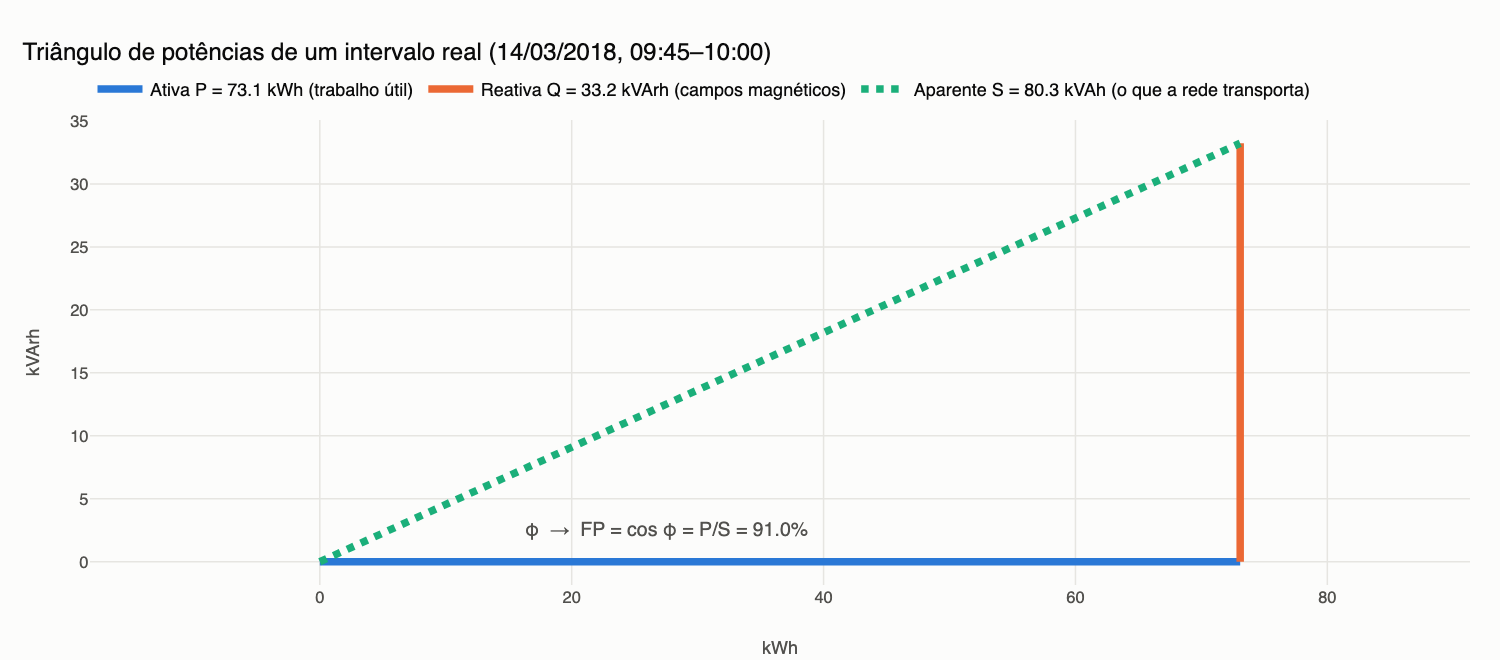

In [8]:
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=[0, P],
        y=[0, 0],
        mode="lines",
        line=dict(width=5, color=CATEGORICAL[0]),
        name=f"Ativa P = {P:.1f} kWh (trabalho útil)",
    )
)
fig.add_trace(
    go.Scatter(
        x=[P, P],
        y=[0, Q],
        mode="lines",
        line=dict(width=5, color=CATEGORICAL[1]),
        name=f"Reativa Q = {Q:.1f} kVArh (campos magnéticos)",
    )
)
fig.add_trace(
    go.Scatter(
        x=[0, P],
        y=[0, Q],
        mode="lines",
        line=dict(width=5, color=CATEGORICAL[2], dash="dot"),
        name=f"Aparente S = {S:.1f} kVAh (o que a rede transporta)",
    )
)
fig.add_annotation(
    x=P * 0.22,
    y=Q * 0.08,
    text=f"φ  →  FP = cos φ = P/S = {P / S:.1%}",
    showarrow=False,
    font=dict(color=TEXT_SECONDARY, size=13),
    xanchor="left",
)
fig.update_layout(
    title="Triângulo de potências de um intervalo real (14/03/2018, 09:45–10:00)",
    xaxis_title="kWh",
    yaxis_title="kVArh",
    hovermode="closest",
    yaxis=dict(scaleanchor="x", scaleratio=1),
    height=440,
)
fig.show()

O FP que calculamos a partir de kWh e kVArh bate com o FP reportado na segunda casa decimal. A seção 6 mostra que isso vale para **todas** as linhas, e isso tem consequências para a modelagem.

### Dicionário das colunas

| Coluna original | Nome no projeto | Unidade | O que é | Observação |
|---|---|---|---|---|
| `date` | `timestamp` | data e hora | Fim do intervalo de 15 min | Formato dd/mm/aaaa. A linha de 00:00 tem a data errada (seção 5) |
| `Usage_kWh` | `usage_kwh` | kWh por 15 min | Energia ativa consumida no intervalo | **Variável-alvo do projeto** |
| `Lagging_Current_Reactive.Power_kVarh` | `lagging_reactive_kvarh` | kVArh por 15 min | Energia reativa indutiva | O nome diz "Power", mas a unidade é energia |
| `Leading_Current_Reactive_Power_kVarh` | `leading_reactive_kvarh` | kVArh por 15 min | Energia reativa capacitiva | Zero em 67% dos intervalos |
| `CO2(tCO2)` | `co2_tco2` | tCO2 por 15 min | Emissão de CO2 atribuída à energia | A UCI diz "ppm", o que está errado. É calculado a partir do kWh (seção 6) |
| `Lagging_Current_Power_Factor` | `lagging_power_factor` | % | FP calculado com o reativo indutivo | É uma função exata de kWh e kVArh |
| `Leading_Current_Power_Factor` | `leading_power_factor` | % | FP calculado com o reativo capacitivo | Vale 100% quando não há reativo capacitivo |
| `NSM` | `nsm` | segundos | *Number of Seconds from Midnight*: segundos desde a meia-noite | Redundante com o horário do timestamp |
| `WeekStatus` | `week_status` | categoria | `Weekday` ou `Weekend` | Não marca feriados. A UCI diz 0/1, mas o arquivo tem texto |
| `Day_of_week` | `day_of_week` | categoria | Dia da semana | Segue o dia em que o intervalo **começa** |
| `Load_Type` | `load_type` | categoria | `Light_Load`, `Medium_Load`, `Maximum_Load` | Faixa horária tarifária, mais uma marcação de dias "parados" (seção 9) |

Vamos ao resumo estatístico:

In [8]:
numeric_cols = [
    "usage_kwh",
    "lagging_reactive_kvarh",
    "leading_reactive_kvarh",
    "co2_tco2",
    "lagging_power_factor",
    "leading_power_factor",
    "nsm",
]
summary = df[numeric_cols].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
summary["zeros_%"] = (df[numeric_cols] == 0).mean() * 100
summary.round(3)

,count,mean,std,min,1%,25%,50%,75%,99%,max,zeros_%
usage_kwh,35040.0,27.387,33.444,0.0,2.590,3.20,4.57,51.238,122.708,157.18,0.003
lagging_reactive_kvarh,35040.0,13.035,16.306,0.0,0.000,2.30,5.00,22.640,62.903,96.91,20.531
leading_reactive_kvarh,35040.0,3.871,7.424,0.0,0.000,0.00,0.00,2.090,26.390,27.76,67.380
co2_tco2,35040.0,0.012,0.016,0.0,0.000,0.00,0.00,0.020,0.060,0.07,59.903
lagging_power_factor,35040.0,80.578,18.921,0.0,43.524,63.32,87.96,99.022,100.000,100.00,0.003
leading_power_factor,35040.0,84.368,30.457,0.0,15.574,99.70,100.00,100.000,100.000,100.00,0.003
nsm,35040.0,42750.000,24940.534,0.0,0.000,21375.00,42750.00,64125.000,85500.000,85500.00,1.042


In [9]:
print(f"Energia total no ano:   {df['usage_kwh'].sum() / 1000:,.1f} MWh")
print(f"Potência média:         {df['usage_kwh'].mean() * 4:,.1f} kW")
print(f"Maior média de 15 min:  {df['usage_kwh'].max() * 4:,.1f} kW")
for col in ["week_status", "day_of_week", "load_type"]:
    print(f"\n{col}:\n{df[col].value_counts().to_string()}")

Energia total no ano:   959.6 MWh
Potência média:         109.5 kW
Maior média de 15 min:  628.7 kW

week_status:
week_status
Weekday    25056
Weekend     9984

day_of_week:
day_of_week
Monday       5088
Tuesday      4992
Wednesday    4992
Thursday     4992
Friday       4992
Saturday     4992
Sunday       4992

load_type:
load_type
Light_Load      18072
Medium_Load      9696
Maximum_Load     7272


**Observação: a escala.** O consumo é de cerca de 960 MWh no ano, com potência média de cerca de 110 kW e a maior média de 15 minutos em cerca de 630 kW. É uma unidade **pequena**. Um forno elétrico a arco (aciaria) opera em escala de megawatts, ordens de grandeza acima. Combinado com a descrição da UCI (bobinas e chapas), o mais plausível é que esta seja uma unidade de **processamento e acabamento** de aço, não uma aciaria.

Isso importa para a narrativa do projeto. O argumento "aço é energo-intensivo" vale para a siderurgia como setor, mas **não podemos atribuir a esta planta** processos que os dados não mostram (fusão, refino, laminação a quente).

**Observação: as 53 segundas-feiras.** A segunda-feira tem 5.088 linhas e os outros dias têm 4.992, porque 2018 começou e terminou numa segunda: são 53 segundas no ano (53 × 96 = 5.088).

## 4. Qualidade dos dados

O módulo `steelops.data.audit` roda todas as checagens de qualidade e devolve um relatório. Aqui está a versão resumida, rodada sobre o arquivo cru:

In [10]:
audit = run_audit(raw_text, config["schema"])
tl = audit["timeline"]
pd.Series(
    {
        "Linhas": audit["structure"]["n_rows"],
        "Valores ausentes (todas as colunas)": sum(audit["missing_tokens"].values()),
        "Falhas de conversão de tipo": sum(audit["parse_failures"].values()),
        "Timestamps duplicados": tl["n_duplicate_timestamps"],
        "Timestamps faltando na grade de 15 min": tl["n_missing_grid_timestamps"],
        "Arquivo em ordem cronológica?": tl["is_monotonic_increasing"],
        "Passos para trás no tempo": tl["n_backward_steps"],
        "Valores negativos (qualquer coluna)": sum(
            v["n_negative"] for v in audit["numeric_ranges"].values()
        ),
        "FP fora de [0, 100]": audit["power_factor_consistency"]["lagging"]["n_out_of_0_100"]
        + audit["power_factor_consistency"]["leading"]["n_out_of_0_100"],
    }
).to_frame("resultado")

,resultado
Linhas,35040
Valores ausentes (todas as colunas),0
Falhas de conversão de tipo,0
Timestamps duplicados,0
Timestamps faltando na grade de 15 min,0
Arquivo em ordem cronológica?,False
Passos para trás no tempo,365
Valores negativos (qualquer coluna),0
"FP fora de [0, 100]",0


O dataset é **limpo no sentido tradicional**: sem nulos, sem duplicatas, sem buracos na grade de 15 minutos, sem valores negativos. Mas duas linhas da tabela chamam atenção:

- o arquivo **não** está em ordem cronológica;
- há **365 passos para trás no tempo**, um por dia.

Vamos ver como os intervalos entre linhas consecutivas se distribuem:

In [11]:
pd.Series(tl["interval_counts"], name="ocorrências")

-1 days +00:15:00      365
0 days 00:15:00      34310
1 days 00:15:00        364
Name: ocorrências, dtype: int64

34.310 saltos são de 15 minutos, como esperado. Mas há 365 saltos de **−1 dia + 15 min** (para trás) e 364 de **+1 dia + 15 min** (para frente). Isso não é ruído, é um padrão sistemático. A próxima seção explica o que está acontecendo.

Há também **um único intervalo com tudo zerado** (kWh, kVArh e FP): 07/11/2018, das 23:45 às 24:00. Pode ser uma falha de medição ou uma parada real. Com uma ocorrência só, o impacto é desprezível, mas ele fica documentado.

In [12]:
df.loc[
    df["usage_kwh"] == 0,
    [
        "timestamp",
        "usage_kwh",
        "lagging_reactive_kvarh",
        "leading_reactive_kvarh",
        "lagging_power_factor",
    ],
]

,timestamp,usage_kwh,lagging_reactive_kvarh,leading_reactive_kvarh,lagging_power_factor
29855,2018-11-08,0.0,0.0,0.0,0.0


## 5. A armadilha da meia-noite

Olhe as linhas do arquivo original em volta da primeira virada de dia:

In [13]:
first_midnight = df_raw.index[
    (df_raw["timestamp"].dt.hour == 0) & (df_raw["timestamp"].dt.minute == 0)
][0]
df_raw.loc[
    first_midnight - 2 : first_midnight + 2, ["timestamp", "usage_kwh", "nsm", "day_of_week"]
]

,timestamp,usage_kwh,nsm,day_of_week
93,2018-01-01 23:30:00,3.24,84600,Monday
94,2018-01-01 23:45:00,3.67,85500,Monday
95,2018-01-01 00:00:00,3.42,0,Monday
96,2018-01-02 00:15:00,3.20,900,Tuesday
97,2018-01-02 00:30:00,3.85,1800,Tuesday


A linha `2018-01-01 00:00` aparece **depois** de `2018-01-01 23:45`, no fim do dia 1º, e não no começo. Duas hipóteses:

- **A.** O arquivo está fora de ordem, e essa linha é mesmo de 1º de janeiro, 00:00, ou seja, o intervalo das 23:45 do dia 31/12/2017 até a meia-noite.
- **B.** O rótulo está errado: a linha é o intervalo das 23:45 às 24:00 do dia 1º, e o timestamp correto seria `2018-01-02 00:00`.

Os dados decidem. Se a hipótese B estiver certa, o valor dessa linha deve ser **contínuo** com `D 23:45` (o intervalo anterior) e com `D+1 00:15` (o seguinte). Se a hipótese A estiver certa, ele deve ser contínuo com `D 00:15`. Comparamos as diferenças para as 365 meias-noites:

In [14]:
is_mid = (df_raw["timestamp"].dt.hour == 0) & (df_raw["timestamp"].dt.minute == 0)
by_label = df_raw.set_index("timestamp")["usage_kwh"]  # original labels are unique
day = df_raw.loc[is_mid, "timestamp"].dt.normalize()
v_mid = df_raw.loc[is_mid, "usage_kwh"].to_numpy()

neighbours = {
    "D 23:45 (hipótese B: vizinho anterior)": day + pd.Timedelta("23:45:00"),
    "D+1 00:15 (hipótese B: vizinho seguinte)": day + pd.Timedelta("1D 00:15:00"),
    "D 00:15 (hipótese A: vizinho seguinte)": day + pd.Timedelta("00:15:00"),
}
rows = {}
for name, ts in neighbours.items():
    other = by_label.reindex(ts).to_numpy()
    ok = ~np.isnan(other)
    rows[name] = {
        "diferença absoluta mediana (kWh)": np.median(np.abs(v_mid[ok] - other[ok])),
        "diferença absoluta média (kWh)": np.mean(np.abs(v_mid[ok] - other[ok])),
    }
rows["referência: dois intervalos consecutivos quaisquer"] = {
    "diferença absoluta mediana (kWh)": np.median(np.abs(np.diff(df["usage_kwh"]))),
    "diferença absoluta média (kWh)": np.mean(np.abs(np.diff(df["usage_kwh"]))),
}
pd.DataFrame(rows).T.round(3)

,diferença absoluta mediana (kWh),diferença absoluta média (kWh)
D 23:45 (hipótese B: vizinho anterior),0.07,1.250
D+1 00:15 (hipótese B: vizinho seguinte),0.07,1.297
D 00:15 (hipótese A: vizinho seguinte),0.39,4.147
referência: dois intervalos consecutivos quaisquer,0.43,6.311


**Hipótese B confirmada.** A linha rotulada `D 00:00` difere em mediana só 0,07 kWh de `D 23:45` e de `D+1 00:15`. De `D 00:15` ela difere 0,39 kWh, praticamente o mesmo que dois intervalos consecutivos quaisquer. Ou seja, ela pertence ao fim do dia D.

Mais duas evidências independentes apontam na mesma direção:
- o `Day_of_week` dessa linha é o dia D, o mesmo do intervalo que vai das 23:45 às 24:00 de D;
- a posição no arquivo, logo depois de `D 23:45`.

O gráfico abaixo mostra o dia em que o efeito é mais visível:

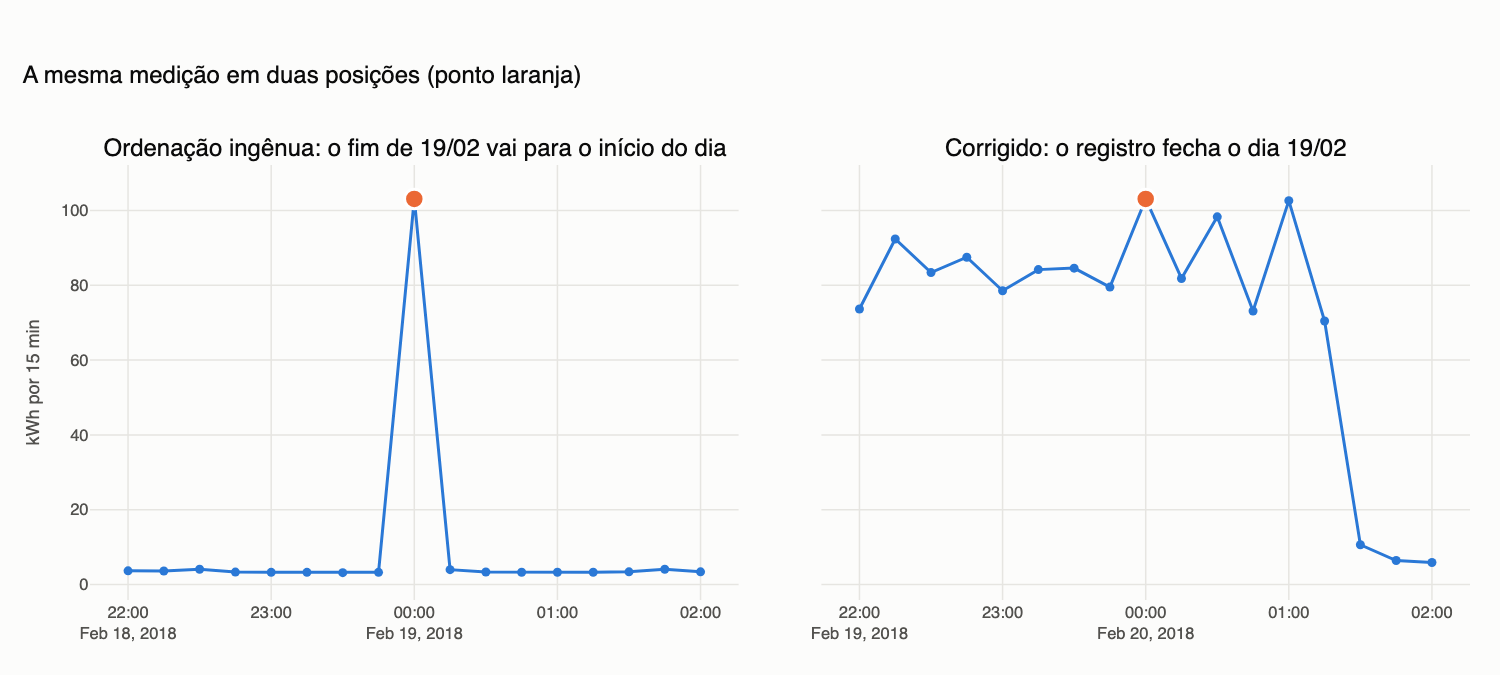

In [15]:
# Pick the day where the misplaced value differs most from D 00:15 (most visible case).
gap_vs_start = np.abs(v_mid - by_label.reindex(day + pd.Timedelta("00:15:00")).to_numpy())
d0 = day.iloc[int(np.nanargmax(gap_vs_start))]

naive = df_raw.sort_values("timestamp").set_index("timestamp")["usage_kwh"]
fixed = df.set_index("timestamp")["usage_kwh"]

fig = make_subplots(
    rows=1,
    cols=2,
    shared_yaxes=True,
    horizontal_spacing=0.06,
    subplot_titles=(
        f"Ordenação ingênua: o fim de {d0:%d/%m} vai para o início do dia",
        f"Corrigido: o registro fecha o dia {d0:%d/%m}",
    ),
)
w1 = naive.loc[d0 - pd.Timedelta("2h") : d0 + pd.Timedelta("2h")]
w2 = fixed.loc[d0 + pd.Timedelta("22h") : d0 + pd.Timedelta("26h")]
fig.add_trace(
    go.Scatter(
        x=w1.index,
        y=w1.values,
        mode="lines+markers",
        line=dict(color=CATEGORICAL[0], width=2),
        marker=dict(size=6),
        name="ordenação ingênua",
    ),
    row=1,
    col=1,
)
fig.add_trace(
    go.Scatter(
        x=[d0],
        y=[naive.loc[d0]],
        mode="markers",
        marker=dict(size=13, color=CATEGORICAL[1], line=dict(color="white", width=2)),
        name=f"linha rotulada {d0:%d/%m} 00:00",
    ),
    row=1,
    col=1,
)
fig.add_trace(
    go.Scatter(
        x=w2.index,
        y=w2.values,
        mode="lines+markers",
        line=dict(color=CATEGORICAL[0], width=2),
        marker=dict(size=6),
        showlegend=False,
    ),
    row=1,
    col=2,
)
moved = d0 + pd.Timedelta("1D")
fig.add_trace(
    go.Scatter(
        x=[moved],
        y=[fixed.loc[moved]],
        mode="markers",
        marker=dict(size=13, color=CATEGORICAL[1], line=dict(color="white", width=2)),
        showlegend=False,
    ),
    row=1,
    col=2,
)
fig.update_yaxes(title_text="kWh por 15 min", row=1, col=1)
fig.update_layout(
    title="A mesma medição em duas posições (ponto laranja)",
    hovermode="closest",
    height=450,
    showlegend=False,
    margin=dict(t=110),
)
fig.show()

**Por que isso importa tanto.** Com a ordenação ingênua, o consumo das 23:45–24:00 do dia D aparece *antes* das 00:15 do mesmo dia D. Uma feature como "consumo de 15 minutos atrás" estaria usando, nesses pontos, uma informação que só existe quase 24 horas depois. É um **vazamento de dados silencioso**: o modelo melhora no teste e falha em produção. Afeta 1 em cada 96 linhas, pouco o bastante para passar despercebido.

**Como o projeto trata isso.** A função `steelops.data.clean.fix_midnight_labels`:
1. **verifica** o padrão (toda linha de 00:00 precisa vir logo depois de 23:45 da mesma data), e se recusa a corrigir se o padrão não bater;
2. soma 1 dia a essas 365 linhas;
3. **verifica** que o resultado é uma sequência perfeita de 15 em 15 minutos.

O raw continua intocado. Há testes automatizados para os três comportamentos, inclusive um que garante que a função recusa dados já ordenados, porque ordenar antes destrói a evidência.

In [16]:
print("Início:", df["timestamp"].min(), "| Fim:", df["timestamp"].max())
print("Ordem cronológica:", df["timestamp"].is_monotonic_increasing)
print(
    "Todos os passos são de 15 min:",
    (df["timestamp"].diff().dropna() == pd.Timedelta("15min")).all(),
)

Início: 2018-01-01 00:15:00 | Fim: 2019-01-01 00:00:00
Ordem cronológica: True
Todos os passos são de 15 min: True


**Convenção adotada no projeto:**
- `timestamp` é o **fim** do intervalo, e o consumo é medido de `timestamp − 15 min` até `timestamp`;
- `interval_start` é o **início** do intervalo. O calendário (`Day_of_week`, `WeekStatus`) segue o início. Daqui em diante, toda análise por hora do dia usa `interval_start`. Assim, "hora 12" significa o consumo entre 12:00 e 13:00.

## 6. Colunas que são cópias disfarçadas do alvo

### Fator de potência é uma identidade matemática

Se o FP reportado for sempre igual a $P/\sqrt{P^2+Q^2}$, ele não é uma medição independente: é uma **conta feita sobre o próprio alvo**.

Diferença máxima entre FP calculado e FP reportado: 0.0050 pontos percentuais
(o arredondamento em 2 casas decimais explica até 0,005)


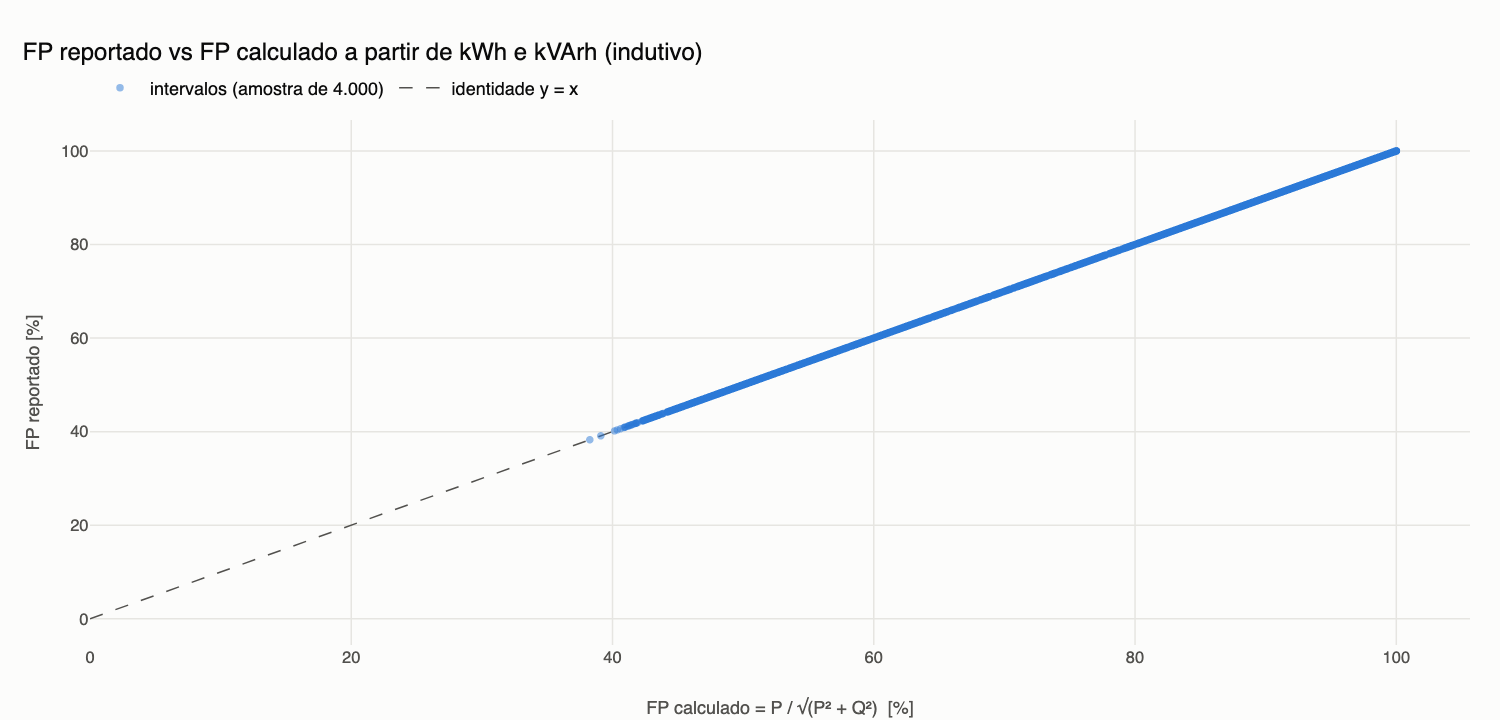

In [17]:
implied_lag = implied_power_factor(df["usage_kwh"], df["lagging_reactive_kvarh"])
residual = (implied_lag - df["lagging_power_factor"]).abs()
print(
    f"Diferença máxima entre FP calculado e FP reportado: {residual.max():.4f} pontos percentuais"
)
print("(o arredondamento em 2 casas decimais explica até 0,005)")

sample = df.assign(implied=implied_lag).dropna(subset=["implied"]).sample(4000, random_state=0)
fig = go.Figure(
    go.Scattergl(
        x=sample["implied"],
        y=sample["lagging_power_factor"],
        mode="markers",
        marker=dict(size=5, color=CATEGORICAL[0], opacity=0.5),
        name="intervalos (amostra de 4.000)",
    )
)
fig.add_trace(
    go.Scatter(
        x=[0, 100],
        y=[0, 100],
        mode="lines",
        line=dict(color=TEXT_SECONDARY, dash="dash", width=1),
        name="identidade y = x",
    )
)
fig.update_layout(
    title="FP reportado vs FP calculado a partir de kWh e kVArh (indutivo)",
    xaxis_title="FP calculado = P / √(P² + Q²)  [%]",
    yaxis_title="FP reportado [%]",
    hovermode="closest",
    height=480,
)
fig.show()

Todos os pontos caem sobre a diagonal. **Consequência:** conhecer o FP e o kVArh de um intervalo é o mesmo que conhecer o kWh dele, porque $P = Q \cdot \text{FP}/\sqrt{1-\text{FP}^2}$. Usar o FP do intervalo-alvo para prever o kWh do intervalo-alvo é reconstruir a resposta, não prever. FPs **passados** não são vazamento, mas também não trazem informação nova além dos kWh e kVArh passados.

### CO2 é o kWh multiplicado por um fator fixo

In [18]:
factor_grid = np.arange(0.000400, 0.000550, 0.000001)
match = [(np.round(df["usage_kwh"] * f + 1e-12, 2) == df["co2_tco2"]).mean() for f in factor_grid]
best = factor_grid[int(np.argmax(match))]
print(f"Fator que melhor reproduz a coluna: {best * 1000:.3f} tCO2/MWh")
print(f"Linhas reproduzidas exatamente por round(kWh x fator, 2): {max(match):.2%}")
print(f"Valores distintos de CO2 no ano inteiro: {sorted(df['co2_tco2'].unique())}")

mismatch = df[np.round(df["usage_kwh"] * best + 1e-12, 2) != df["co2_tco2"]]
print(f"\n{len(mismatch)} linhas não batem. Datas com mais divergências:")
print(mismatch["interval_start"].dt.date.value_counts().head(5).to_string())

Fator que melhor reproduz a coluna: 0.459 tCO2/MWh
Linhas reproduzidas exatamente por round(kWh x fator, 2): 99.75%
Valores distintos de CO2 no ano inteiro: [np.float64(0.0), np.float64(0.01), np.float64(0.02), np.float64(0.03), np.float64(0.04), np.float64(0.05), np.float64(0.06), np.float64(0.07)]

88 linhas não batem. Datas com mais divergências:
interval_start
2018-01-02    47
2018-01-18     1
2018-01-27     1
2018-01-31     1
2018-02-06     1


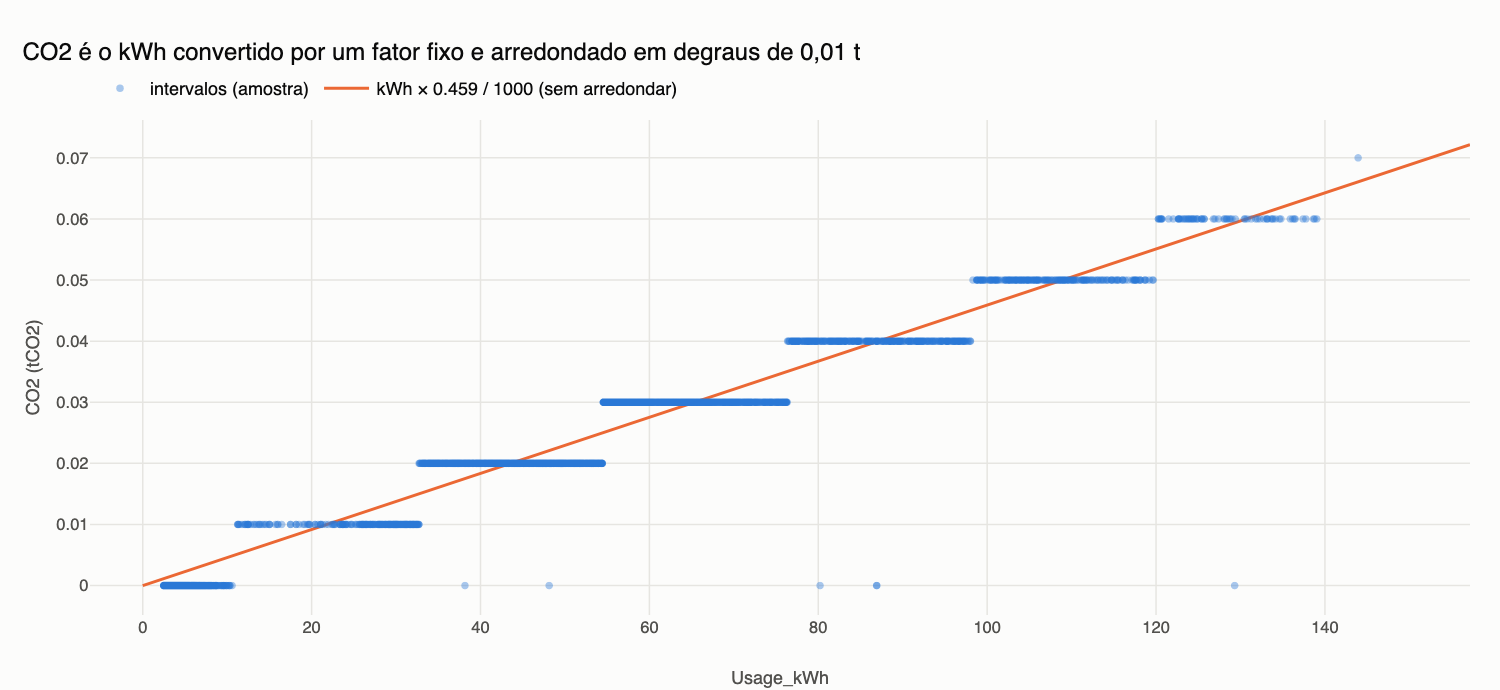

In [19]:
sample = df.sample(6000, random_state=1)
fig = go.Figure(
    go.Scattergl(
        x=sample["usage_kwh"],
        y=sample["co2_tco2"],
        mode="markers",
        marker=dict(size=5, color=CATEGORICAL[0], opacity=0.4),
        name="intervalos (amostra)",
    )
)
xs = np.linspace(0, df["usage_kwh"].max(), 200)
fig.add_trace(
    go.Scatter(
        x=xs,
        y=xs * best,
        mode="lines",
        line=dict(color=CATEGORICAL[1], width=2),
        name=f"kWh × {best * 1000:.3f} / 1000 (sem arredondar)",
    )
)
fig.update_layout(
    title="CO2 é o kWh convertido por um fator fixo e arredondado em degraus de 0,01 t",
    xaxis_title="Usage_kWh",
    yaxis_title="CO2 (tCO2)",
    hovermode="closest",
    height=460,
)
fig.show()

**Observação.** A coluna `CO2(tCO2)` é `round(kWh × 0,459 / 1000, 2)` em 99,75% das linhas. Das 88 exceções, 47 estão num único bloco na manhã de 02/01, quando o CO2 ficou zerado com a planta operando (provável falha no canal de CO2). As outras são linhas isoladas. Assim:

- a unidade é **tCO2 por intervalo** (como diz o nome da coluna), e **não ppm** (como diz a página da UCI). Uma concentração em ppm não seria proporcional ao consumo de energia da planta;
- o fator implícito, cerca de 0,459 tCO2/MWh, tem a ordem de grandeza de um fator de emissão de rede elétrica com geração majoritariamente fóssil. **Não encontrei uma fonte oficial confirmando o valor exato**, então ele fica registrado como inferido;
- como só existem 8 valores possíveis (0 a 0,07), a coluna é uma versão **degradada** do kWh. Não acrescenta nenhuma informação.

Essa é a explicação dos R² de 0,99 que aparecem em tantos notebooks públicos: o modelo recebe a resposta por outra porta.

## 7. Como a planta consome energia

### A distribuição tem duas populações

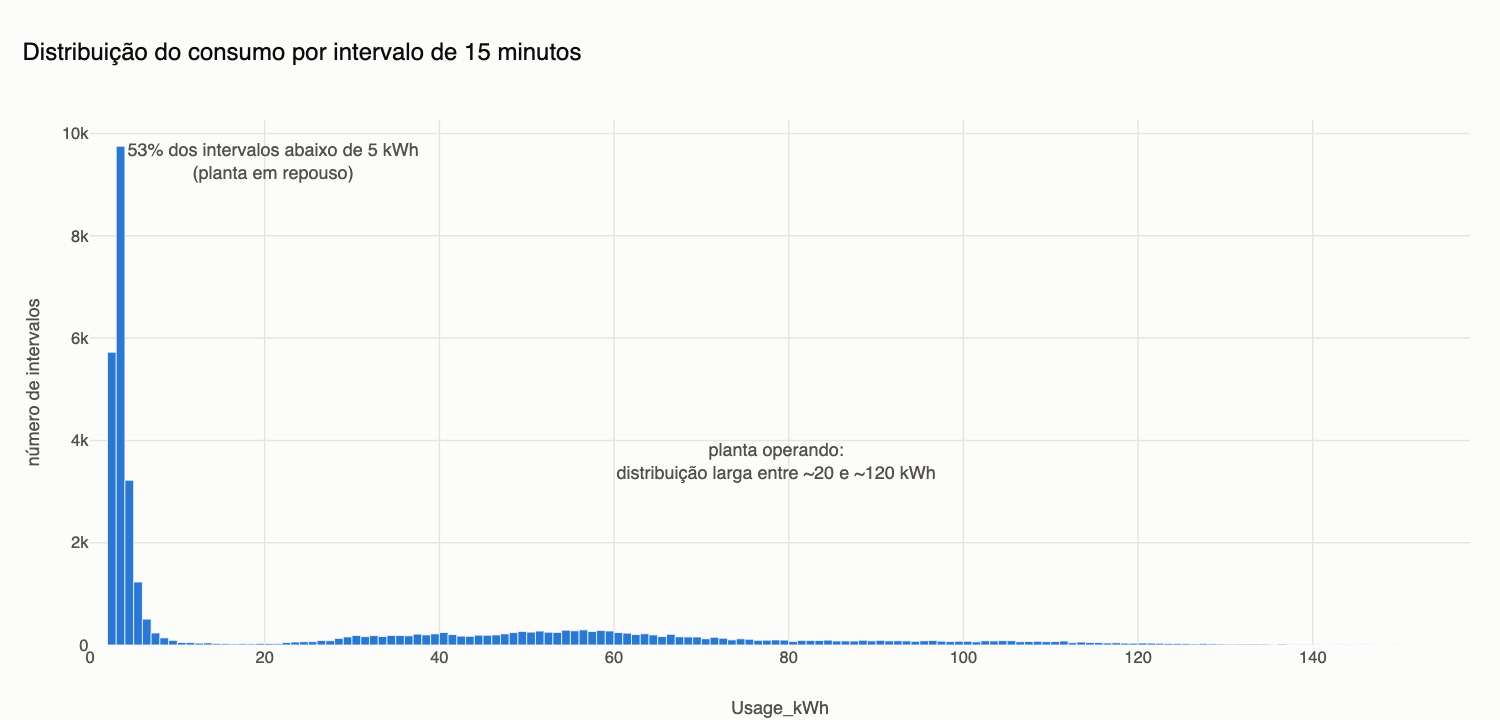

In [20]:
fig = go.Figure(
    go.Histogram(
        x=df["usage_kwh"],
        xbins=dict(start=0, end=160, size=1),
        marker=dict(color=CATEGORICAL[0], line=dict(color="white", width=0.5)),
        name="intervalos",
    )
)
share_idle = (df["usage_kwh"] < 5).mean()
fig.add_annotation(
    x=4,
    y=0.97,
    yref="paper",
    text=f"{share_idle:.0%} dos intervalos abaixo de 5 kWh<br>(planta em repouso)",
    showarrow=False,
    xanchor="left",
    font=dict(color=TEXT_SECONDARY),
)
fig.add_annotation(
    x=60,
    y=0.35,
    yref="paper",
    text="planta operando:<br>distribuição larga entre ~20 e ~120 kWh",
    showarrow=False,
    xanchor="left",
    font=dict(color=TEXT_SECONDARY),
)
fig.update_layout(
    title="Distribuição do consumo por intervalo de 15 minutos",
    xaxis_title="Usage_kWh",
    yaxis_title="número de intervalos",
    hovermode="closest",
    bargap=0,
    showlegend=False,
)
fig.show()

**Observação.** A série é **bimodal**. Mais da metade do tempo, a planta está num patamar de repouso de cerca de 3 a 4 kWh por 15 minutos, ou seja, uns 12 a 16 kW de carga de base: iluminação, sistemas auxiliares, transformadores energizados. Quando opera, o consumo se espalha numa faixa larga.

Isso tem uma implicação direta: a média (27 kWh) **não representa nenhum estado real** da planta. É uma série do tipo "liga/desliga", e prever *quando* a planta muda de estado é provavelmente a parte mais difícil e mais valiosa do problema.

### O ano inteiro, dia a dia

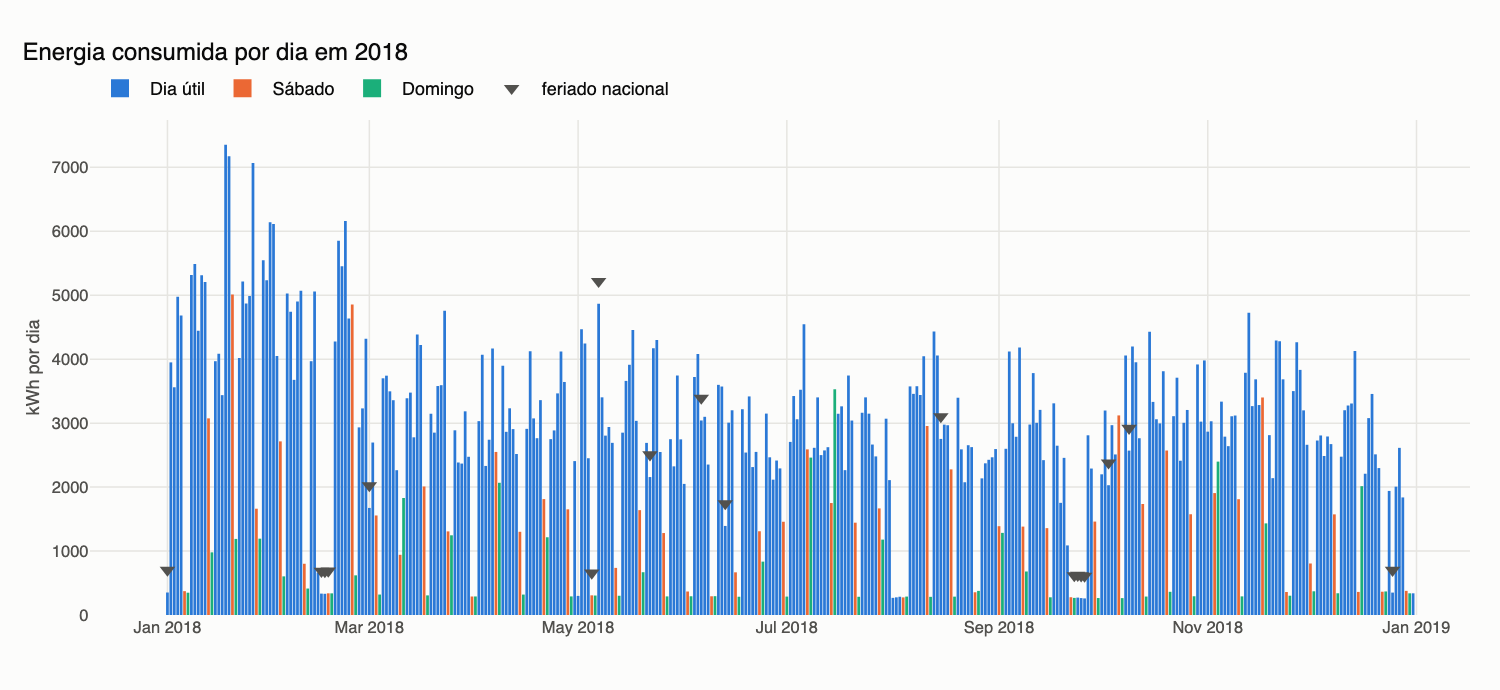

In [21]:
kr_holidays = holidays.KR(years=2018, language="en_US")
daily = (
    df.assign(day=df["interval_start"].dt.normalize()).groupby("day").agg(kwh=("usage_kwh", "sum"))
)
daily["dow"] = daily.index.day_name()
daily["holiday"] = [kr_holidays.get(d.date()) for d in daily.index]
daily["day_type"] = np.select(
    [daily["dow"].eq("Sunday"), daily["dow"].eq("Saturday")], ["Domingo", "Sábado"], "Dia útil"
)

fig = go.Figure()
for i, label in enumerate(["Dia útil", "Sábado", "Domingo"]):
    sub = daily[daily["day_type"] == label]
    fig.add_trace(
        go.Bar(
            x=sub.index,
            y=sub["kwh"],
            name=label,
            width=0.8 * 86_400_000,  # 0.8 day in ms
            marker=dict(color=CATEGORICAL[i], line=dict(width=0)),
            hovertemplate="%{x|%a %d/%m}: %{y:,.0f} kWh<extra>" + label + "</extra>",
        )
    )
hol = daily[daily["holiday"].notna()]
fig.add_trace(
    go.Scatter(
        x=hol.index,
        y=hol["kwh"] + 350,
        mode="markers",
        name="feriado nacional",
        marker=dict(symbol="triangle-down", size=9, color=TEXT_SECONDARY),
        customdata=hol["holiday"],
        hovertemplate="%{x|%d/%m}: feriado<extra></extra>",
    )
)
fig.update_layout(
    title="Energia consumida por dia em 2018",
    yaxis_title="kWh por dia",
    barmode="overlay",
    bargap=0.15,
    hovermode="closest",
    height=460,
)
fig.show()

**Observações:**
- Metade dos dias úteis fica entre cerca de 2.600 e 3.900 kWh (mediana de 3.119), sábados em cerca de metade disso, e domingos perto do patamar de repouso, mas **nem todo domingo é parado**.
- Há **paradas longas** visíveis: o Seollal (Ano Novo Lunar, meados de fevereiro), o início de agosto e o Chuseok (fim de setembro).
- Janeiro tem os dias de maior consumo do ano. Dezembro termina com consumo baixo.
- **Nem todo feriado nacional é dia parado.** A tabela abaixo mostra que alguns feriados tiveram consumo de dia útil normal.

In [22]:
weekday_median = daily.loc[daily["day_type"] == "Dia útil", "kwh"].median()
hol_table = daily.loc[daily["holiday"].notna(), ["holiday", "dow", "kwh"]].rename(
    columns={"holiday": "feriado", "dow": "dia da semana", "kwh": "kWh no dia"}
)
hol_table["% da mediana de um dia útil"] = (100 * hol_table["kWh no dia"] / weekday_median).round(0)
print(f"Mediana de um dia útil: {weekday_median:,.0f} kWh")
hol_table.round(0)

Mediana de um dia útil: 3,119 kWh


,feriado,dia da semana,kWh no dia,% da mediana de um dia útil
day,,,,
2018-01-01,New Year's Day,Monday,352.0,11.0
2018-02-15,The day preceding Korean New Year,Thursday,335.0,11.0
2018-02-16,Korean New Year,Friday,332.0,11.0
2018-02-17,The second day of Korean New Year,Saturday,339.0,11.0
2018-03-01,Independence Movement Day,Thursday,1674.0,54.0
2018-05-05,Children's Day,Saturday,307.0,10.0
2018-05-07,Alternative holiday for Children's Day,Monday,4869.0,156.0
2018-05-22,Buddha's Birthday,Tuesday,2157.0,69.0
2018-06-06,Memorial Day,Wednesday,3042.0,98.0


**Observação.** Ano Novo, Seollal, Dia das Crianças, Chuseok e Natal foram dias parados (cerca de 260 a 350 kWh). Já o feriado substituto de 7 de maio, o Dia da Memória (6/6) e o Dia da Libertação (15/8) tiveram consumo de dia útil normal. **O calendário de feriados nacionais ajuda, mas não é o calendário de operação da planta.** Uma feature de feriado vai acertar parte das paradas e errar outras.

### A impressão digital da planta

Cada coluna é um dia, cada linha é um horário. A cor é o consumo. Esse mapa resume o ano inteiro em uma imagem:

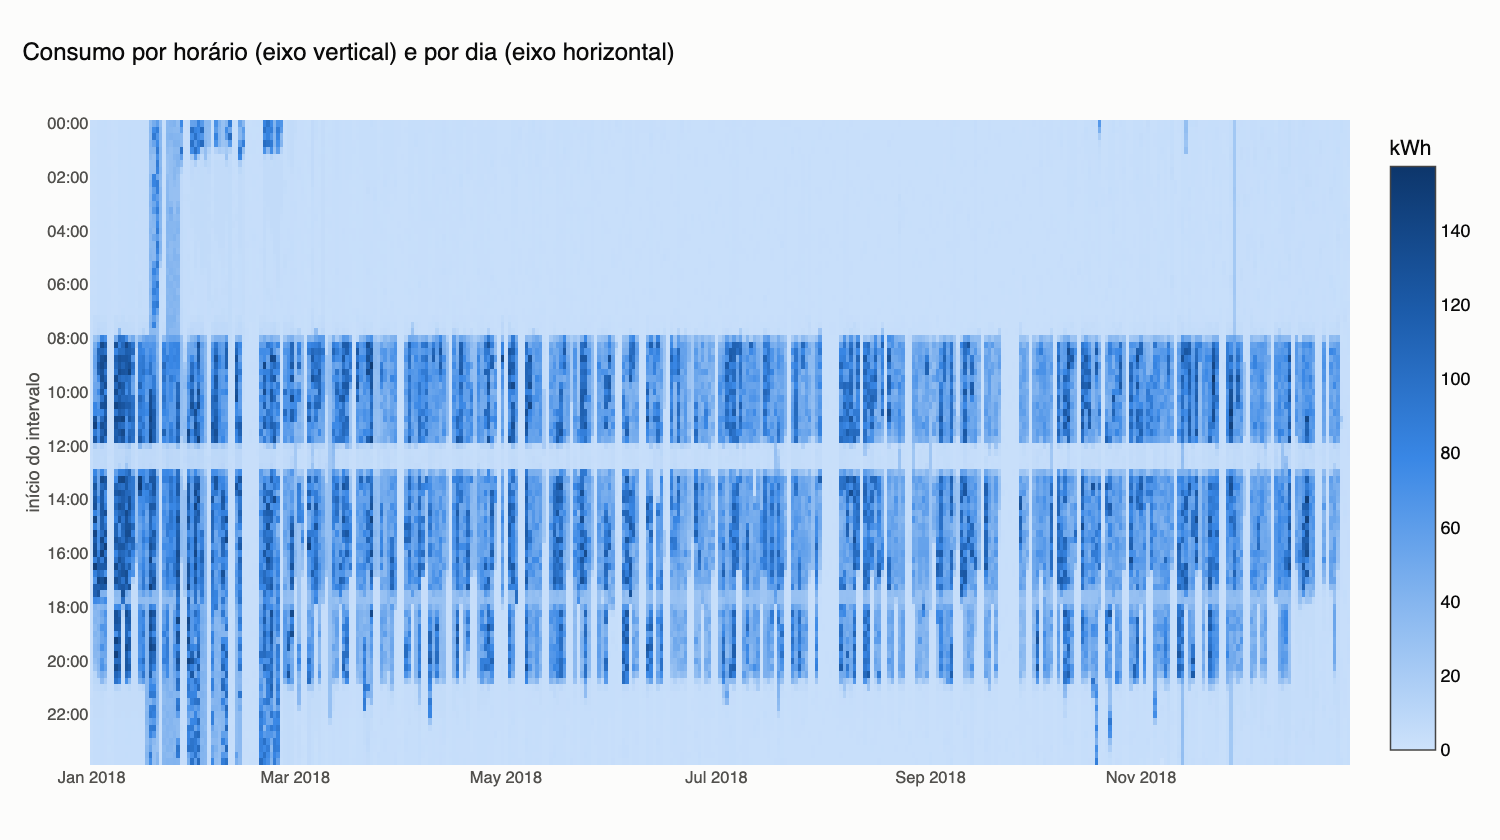

In [23]:
grid = df.pivot_table(
    index=df["interval_start"].dt.strftime("%H:%M"),
    columns=df["interval_start"].dt.normalize(),
    values="usage_kwh",
)
fig = go.Figure(
    go.Heatmap(
        z=grid.values,
        x=grid.columns,
        y=grid.index,
        colorscale=SEQUENTIAL_BLUE,
        colorbar=dict(title="kWh"),
        hovertemplate="%{x|%a %d/%m} %{y}: %{z:.1f} kWh<extra></extra>",
    )
)
fig.update_layout(
    title="Consumo por horário (eixo vertical) e por dia (eixo horizontal)",
    yaxis=dict(autorange="reversed", nticks=13, title="início do intervalo"),
    hovermode="closest",
    height=560,
)
fig.show()

**Observações:**
- As **listras verticais claras** são fins de semana e paradas. A cadência semanal é a estrutura mais forte do dataset.
- Há uma **faixa horizontal clara ao meio-dia** e outra por volta das 21h. A planta para nesses horários, todos os dias úteis.
- Há também uma faixa clara mais estreita por volta das 17h45: uma pausa curta entre o expediente da tarde e o da noite.
- **Em janeiro e fevereiro a planta operou de madrugada** em vários dias (manchas escuras no topo e no pé do mapa). A partir de março isso praticamente desaparece: o consumo médio entre 0h e 6h cai de cerca de 16 kWh em janeiro para cerca de 3 kWh no resto do ano. É uma mudança de regime operacional *dentro* do período de treino, e o modelo precisa lidar com ela.

### O dia típico

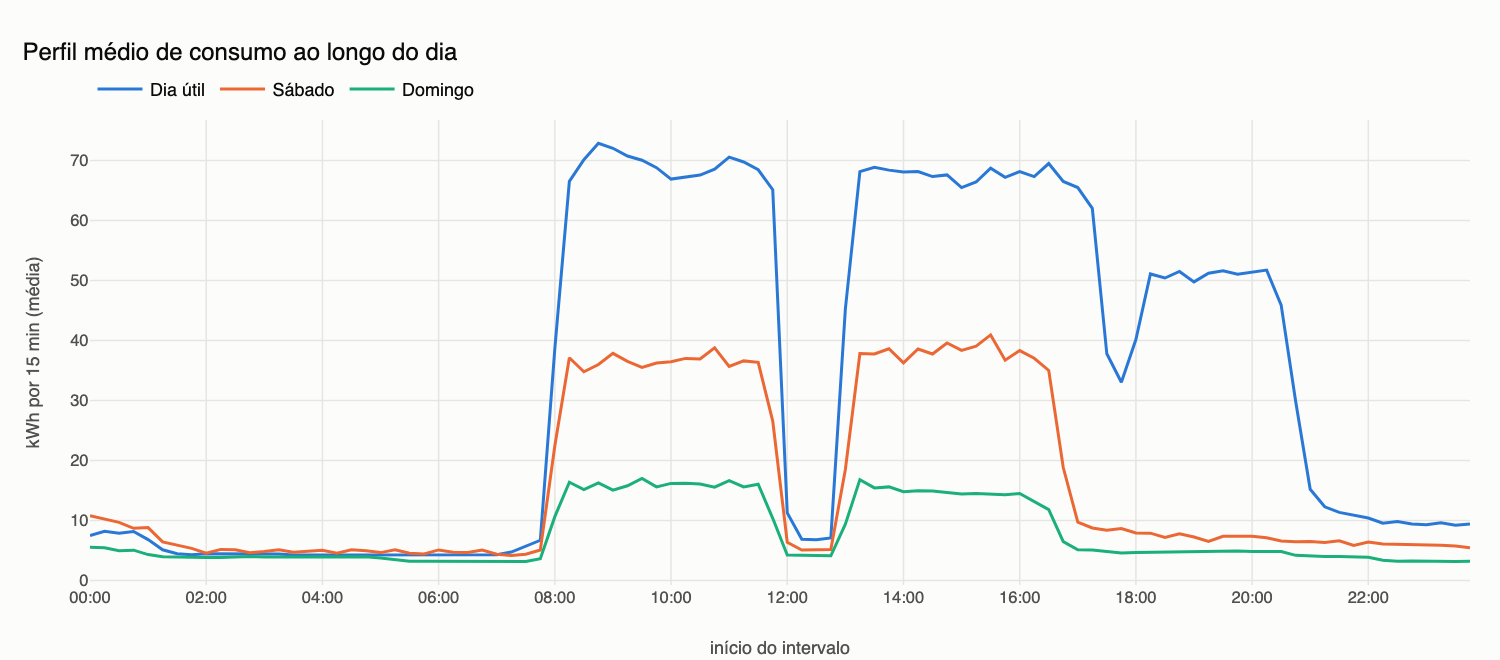

In [24]:
tod = df["interval_start"].dt.strftime("%H:%M")
dtype = np.select(
    [df["day_of_week"].eq("Sunday"), df["day_of_week"].eq("Saturday")],
    ["Domingo", "Sábado"],
    "Dia útil",
)
profile = (
    df.assign(tod=tod, day_type=dtype).groupby(["day_type", "tod"])["usage_kwh"].mean().unstack(0)
)

fig = go.Figure()
for i, label in enumerate(["Dia útil", "Sábado", "Domingo"]):
    fig.add_trace(
        go.Scatter(
            x=profile.index,
            y=profile[label],
            mode="lines",
            name=label,
            line=dict(color=CATEGORICAL[i], width=2),
        )
    )
fig.update_layout(
    title="Perfil médio de consumo ao longo do dia",
    xaxis_title="início do intervalo",
    yaxis_title="kWh por 15 min (média)",
    xaxis=dict(nticks=13),
    height=440,
)
fig.show()

**Observações:**
- Num dia útil, o consumo sobe às **08h**, fica num patamar alto até as **12h**, cai fortemente entre **12h e 13h**, volta das **13h às 17h**, tem uma queda curta por volta das **17h30–18h**, segue num patamar intermediário (cerca de 50 kWh) até as **21h** e cai depois disso.
- O sábado tem o mesmo formato, mas mais baixo e terminando às 17h. O domingo, em média, é quase só o patamar de repouso.

**Hipótese:** o desenho é compatível com uma jornada diurna com pausa para almoço das 12h às 13h e um segundo turno, ou turno estendido, até as 21h. O dataset **não tem** informação de turnos, produção ou equipamentos, então isso é uma interpretação, não um fato.

## 8. O comportamento elétrico: reativos e fator de potência

Agora olhamos as três grandezas juntas, no mesmo eixo de tempo, em dias úteis. São três painéis separados porque as unidades são diferentes:

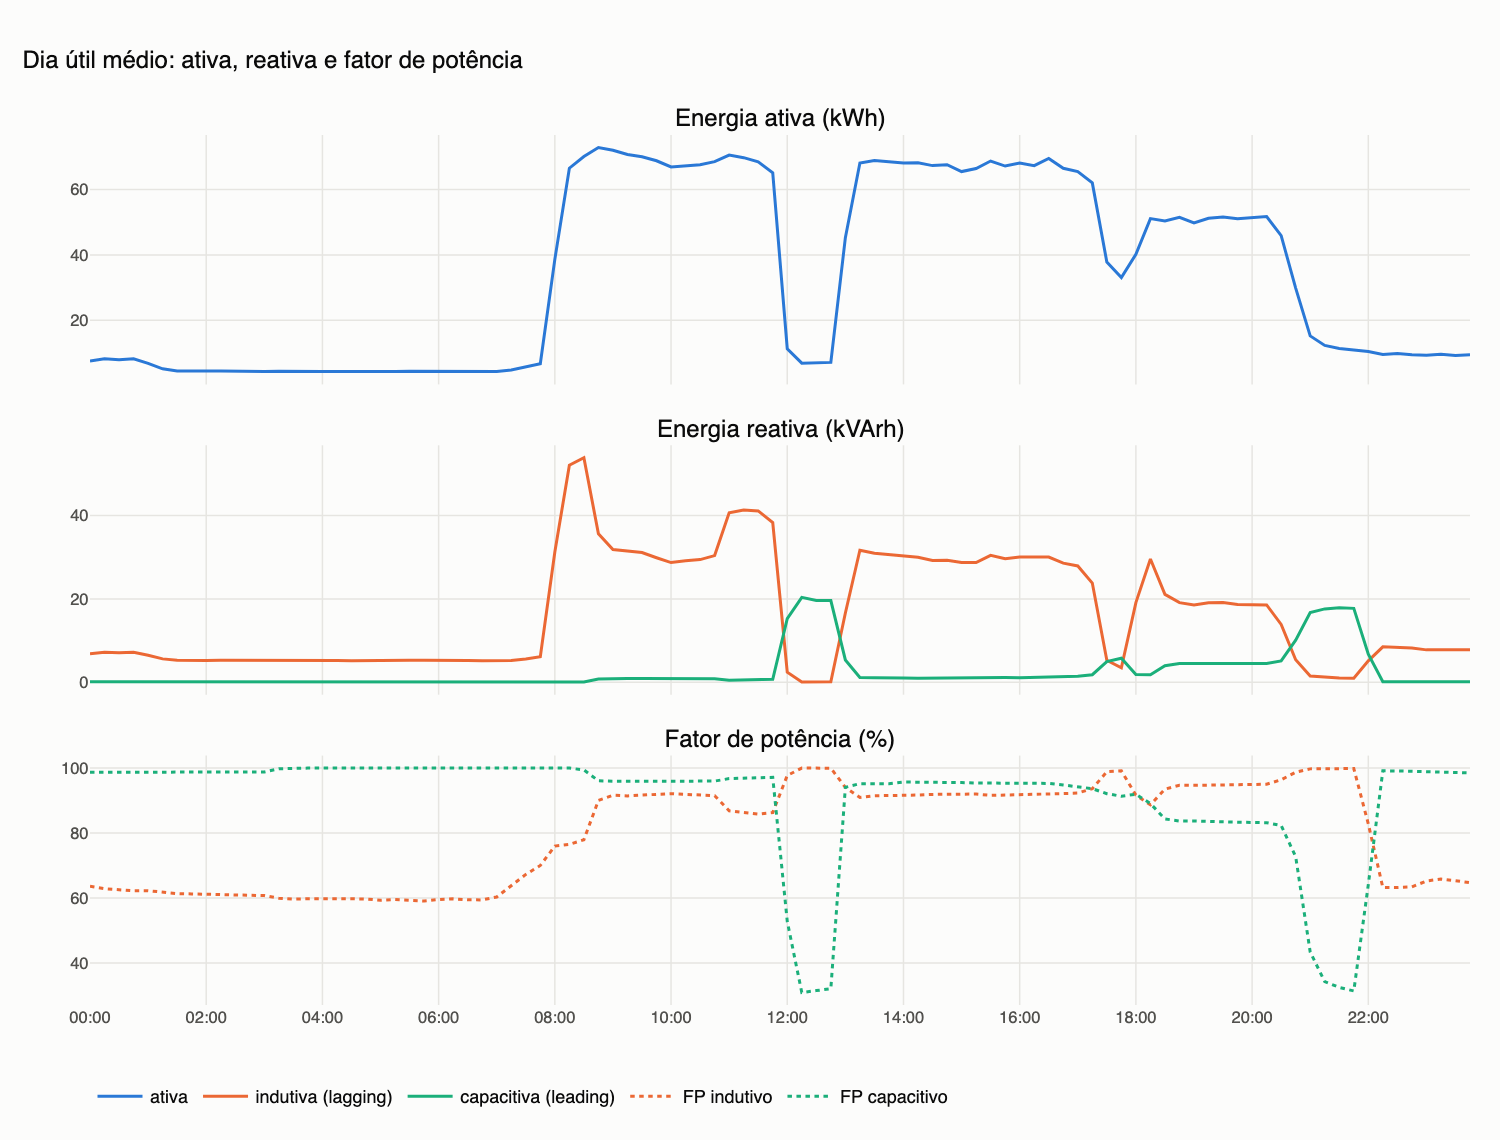

In [25]:
wk = df[df["day_of_week"].isin(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"])].copy()
wk["tod"] = wk["interval_start"].dt.strftime("%H:%M")
g = wk.groupby("tod")[
    [
        "usage_kwh",
        "lagging_reactive_kvarh",
        "leading_reactive_kvarh",
        "lagging_power_factor",
        "leading_power_factor",
    ]
].mean()

fig = make_subplots(
    rows=3,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.07,
    subplot_titles=("Energia ativa (kWh)", "Energia reativa (kVArh)", "Fator de potência (%)"),
)
fig.add_trace(
    go.Scatter(x=g.index, y=g["usage_kwh"], name="ativa", line=dict(color=CATEGORICAL[0], width=2)),
    1,
    1,
)
fig.add_trace(
    go.Scatter(
        x=g.index,
        y=g["lagging_reactive_kvarh"],
        name="indutiva (lagging)",
        line=dict(color=CATEGORICAL[1], width=2),
    ),
    2,
    1,
)
fig.add_trace(
    go.Scatter(
        x=g.index,
        y=g["leading_reactive_kvarh"],
        name="capacitiva (leading)",
        line=dict(color=CATEGORICAL[2], width=2),
    ),
    2,
    1,
)
fig.add_trace(
    go.Scatter(
        x=g.index,
        y=g["lagging_power_factor"],
        name="FP indutivo",
        line=dict(color=CATEGORICAL[1], width=2, dash="dot"),
    ),
    3,
    1,
)
fig.add_trace(
    go.Scatter(
        x=g.index,
        y=g["leading_power_factor"],
        name="FP capacitivo",
        line=dict(color=CATEGORICAL[2], width=2, dash="dot"),
    ),
    3,
    1,
)
fig.update_xaxes(nticks=13)
fig.update_layout(
    title="Dia útil médio: ativa, reativa e fator de potência",
    height=760,
    legend=dict(orientation="h", y=-0.08, yanchor="top"),
    margin=dict(t=90, b=90),
)
fig.show()

**Observações:**
- **De madrugada**, a ativa fica em cerca de 4 kWh e a reativa indutiva em cerca de 5 kVArh. O FP indutivo cai para perto de 60–65%. Com a planta parada, o que sobra são cargas "magnetizantes", como transformadores energizados, que consomem muito reativo em relação à pouca ativa.
- **Durante a operação** (08–12h e 13–17h), a reativa indutiva acompanha a ativa e o FP indutivo sobe.
- **Na partida, por volta das 08h**, a reativa indutiva dá um pico maior que o da operação estável.
- **Às 12h e às 21h**, quando a ativa despenca, a reativa **capacitiva** dá um salto e o FP capacitivo cai para cerca de 30%. Às 12h, praticamente todos os intervalos têm reativo capacitivo.
- **Por volta das 22h**, o reativo capacitivo zera e o indutivo volta ao patamar noturno.

**Hipótese (clássica em engenharia elétrica):** a planta tem bancos de capacitores dimensionados para compensar os motores em operação. Quando os motores param no almoço ou no fim do turno e os capacitores continuam conectados, a compensação "sobra" e a planta passa a injetar reativo capacitivo. É o mesmo fenômeno que leva concessionárias a penalizar FP capacitivo em horários de carga leve. O fato de o reativo capacitivo sumir por volta das 22h é compatível com o banco sendo desligado no fim da jornada. O dataset não informa a existência dos capacitores, mas o padrão é a assinatura típica desse caso. O pico de reativo indutivo às 08h é compatível com a partida de motores e transformadores, que costuma exigir mais corrente magnetizante.

**Para o projeto:** as quedas das 12h e das 21h aparecem tanto na ativa quanto na reativa. O reativo **passado** pode carregar algum sinal sobre o estado da planta, mas como ele se move junto com a ativa, a hipótese mais provável é que acrescente pouco. Isso será testado no Milestone 2, não assumido.

## 9. O `Load_Type` e o calendário

A UCI apresenta `Load_Type` como a variável-alvo de classificação do dataset. Precisamos saber de onde ela vem: se é algo conhecido com antecedência (como uma tabela de horários) ou algo derivado do que aconteceu.

Primeiro, a "tabela" em dias úteis, horário por mês:

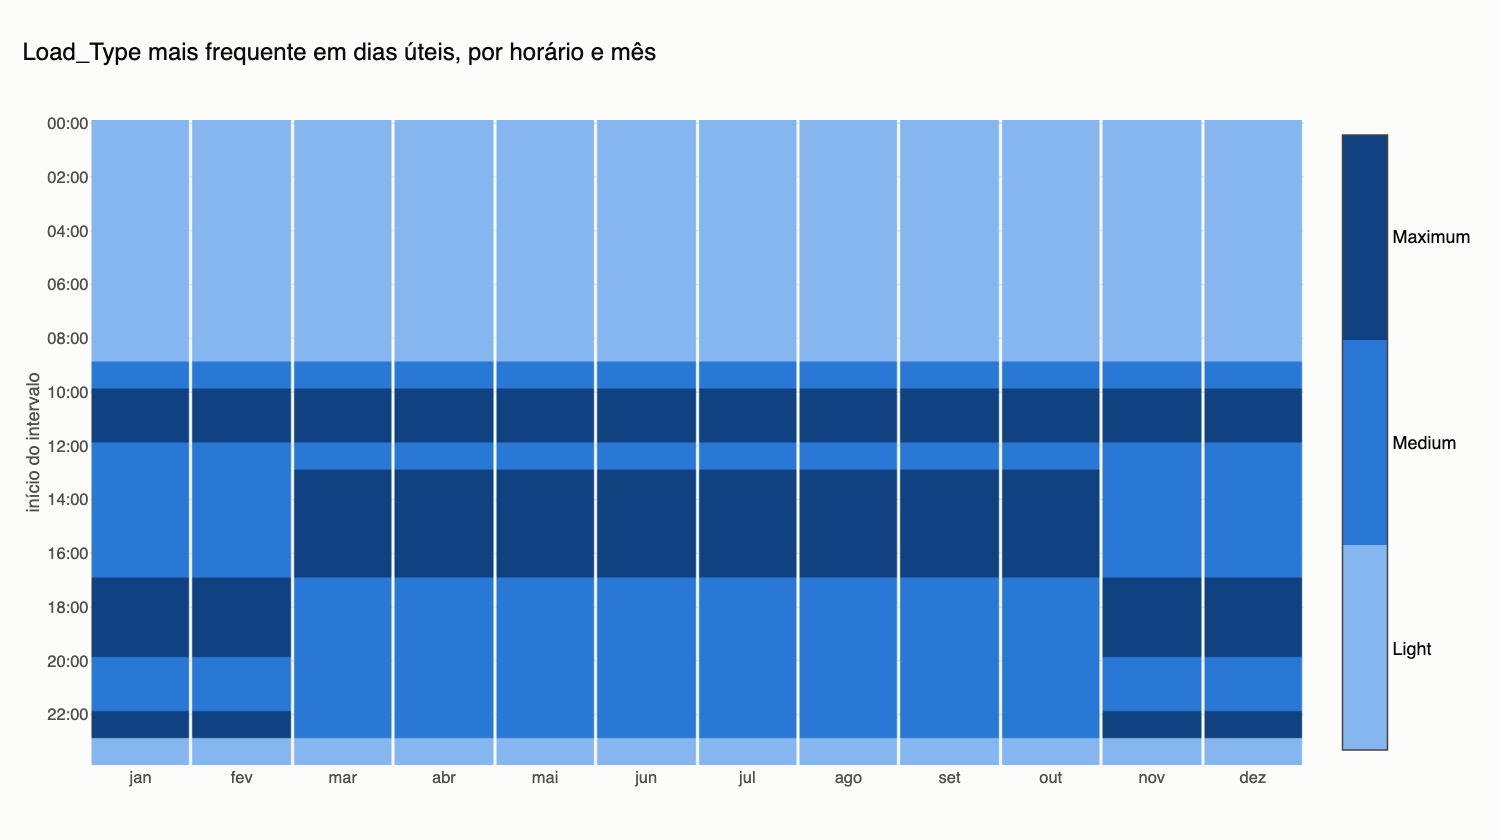

In [26]:
codes = {"Light_Load": 0, "Medium_Load": 1, "Maximum_Load": 2}
wk_lt = wk.assign(month=wk["interval_start"].dt.month, code=wk["load_type"].map(codes))
sched = wk_lt.groupby(["tod", "month"])["code"].agg(lambda s: s.mode().iloc[0]).unstack("month")
months = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
ordinal = [
    [0.0, "#86b6ef"],
    [0.333, "#86b6ef"],
    [0.333, "#2a78d6"],
    [0.666, "#2a78d6"],
    [0.666, "#104281"],
    [1.0, "#104281"],
]
fig = go.Figure(
    go.Heatmap(
        z=sched.values,
        x=months,
        y=sched.index,
        zmin=0,
        zmax=2,
        colorscale=ordinal,
        xgap=2,
        ygap=0,
        colorbar=dict(tickvals=[0.33, 1, 1.67], ticktext=["Light", "Medium", "Maximum"]),
        hovertemplate="%{x} %{y}: %{z}<extra></extra>",
    )
)
fig.update_layout(
    title="Load_Type mais frequente em dias úteis, por horário e mês",
    yaxis=dict(autorange="reversed", nticks=13, title="início do intervalo"),
    hovermode="closest",
    height=560,
)
fig.show()

**Observação.** Em dias úteis, o `Load_Type` segue uma grade fixa:
- **Light** das 23h às 09h, o ano todo;
- **Maximum** das 10h às 12h, o ano todo;
- de março a outubro, Maximum também das 13h às 17h;
- de novembro a fevereiro (inverno), o Maximum se desloca para 17h–20h e 22h–23h.

Esse formato, com faixas leve, intermediária e máxima e um regime de inverno diferente, é a estrutura típica de uma **tarifa horossazonal** (*time-of-use*), como a da KEPCO. A tabela foi inferida dos dados e não confirmada contra o documento tarifário de 2018.

Note que a tabela **não depende do consumo**: às 12h, quando a planta para para almoçar, o rótulo continua "Medium". Dentro de um dia de operação, `Load_Type` é calendário puro.

**Mas há uma segunda camada.** Em alguns dias, o `Load_Type` é "Light" o dia inteiro:

In [27]:
daytime = df[(df["interval_start"].dt.hour >= 10) & (df["interval_start"].dt.hour < 20)]
all_light = daytime.groupby(daytime["interval_start"].dt.normalize())["load_type"].apply(
    lambda s: (s == "Light_Load").all()
)
daily["all_light"] = all_light
daily["categoria"] = np.select(
    [daily["all_light"] & daily["dow"].eq("Sunday"), daily["all_light"], daily["dow"].eq("Sunday")],
    ["domingo, todo Light", "outro dia, todo Light", "domingo, NÃO todo Light"],
    "dia normal",
)
daily.groupby("categoria")["kwh"].describe()[["count", "mean", "min", "50%", "max"]].round(0)

,count,mean,min,50%,max
categoria,,,,,
dia normal,286.0,3191.0,667.0,3061.0,7354.0
"domingo, NÃO todo Light",17.0,1494.0,377.0,1246.0,3530.0
"domingo, todo Light",35.0,351.0,264.0,294.0,1190.0
"outro dia, todo Light",27.0,349.0,259.0,335.0,801.0


**Observação.** 62 dias são "todo Light". São 35 domingos, 14 sábados e 13 dias úteis, incluindo os feriados parados. Ao mesmo tempo, **17 domingos não são** "todo Light", e nesses domingos a planta consumiu em média cerca de 1.500 kWh, ou seja, trabalhou.

Os dias "todo Light" têm consumo de dia parado (cerca de 350 kWh). **A marcação do dia acompanha se a planta operou ou não.** Não sabemos se ela vem de um calendário de produção planejado com antecedência ou se foi atribuída depois, olhando o consumo. Por isso:

- **O `Load_Type` não será usado como feature.** Na previsão de 1 hora, ele provavelmente seria conhecido. Mas na de 24 horas, saber que amanhã é um dia "todo Light" é saber que a planta vai parar, e não temos como provar que essa informação existiria na véspera.
- **A parte determinística (a grade horária) pode ser reconstruída** a partir de hora, mês e dia da semana, que são features de calendário legítimas.

## 10. Memória da série: autocorrelação

A autocorrelação no lag *k* mede o quanto o consumo de agora se parece com o consumo de *k* intervalos atrás. É a pergunta "o passado ajuda a prever?", feita para cada distância no tempo.

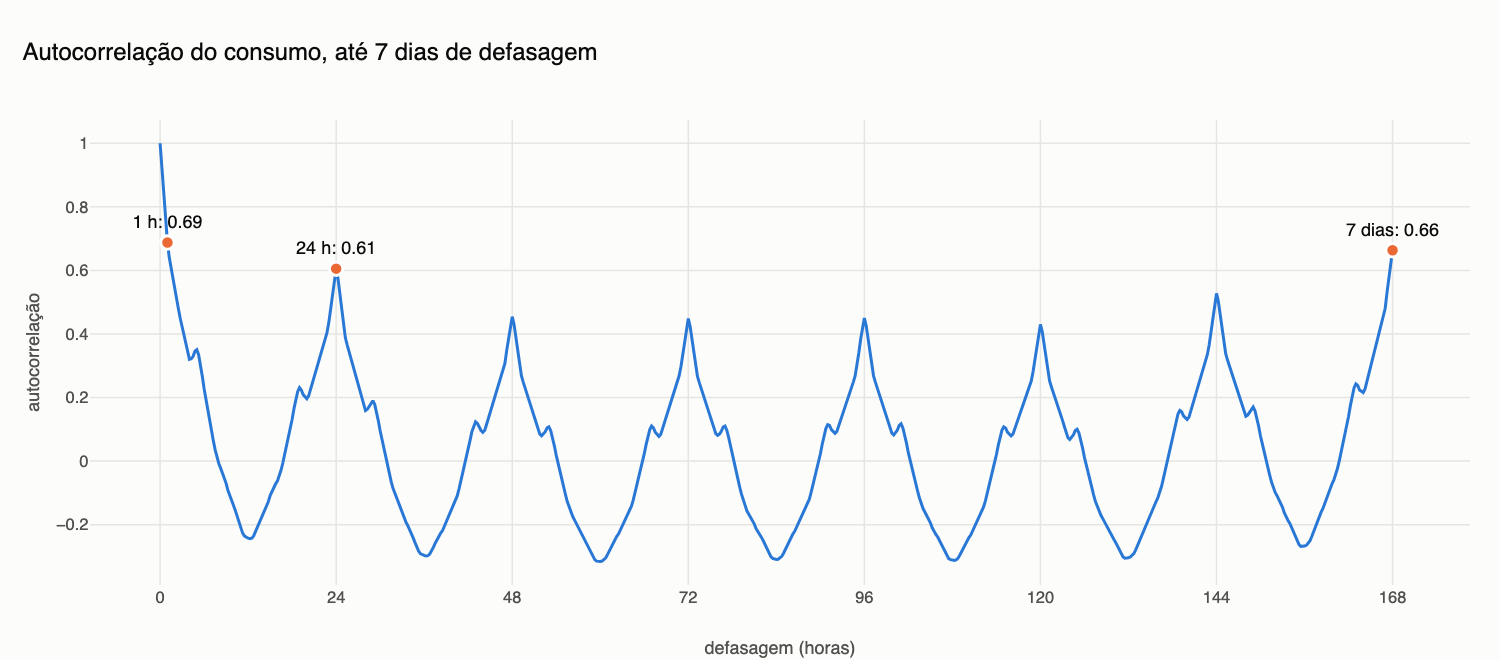

In [28]:
x = df["usage_kwh"].to_numpy() - df["usage_kwh"].mean()
max_lag = 7 * 96
acf = np.array([1.0] + [np.dot(x[:-k], x[k:]) / np.dot(x, x) for k in range(1, max_lag + 1)])
lags_h = np.arange(max_lag + 1) / 4

fig = go.Figure(
    go.Scatter(x=lags_h, y=acf, mode="lines", line=dict(color=CATEGORICAL[0], width=2), name="ACF")
)
for k, label in [(4, "1 h"), (96, "24 h"), (672, "7 dias")]:
    fig.add_trace(
        go.Scatter(
            x=[k / 4],
            y=[acf[k]],
            mode="markers+text",
            text=[f"{label}: {acf[k]:.2f}"],
            textposition="top center",
            marker=dict(size=9, color=CATEGORICAL[1], line=dict(color="white", width=2)),
            showlegend=False,
        )
    )
fig.update_layout(
    title="Autocorrelação do consumo, até 7 dias de defasagem",
    xaxis_title="defasagem (horas)",
    yaxis_title="autocorrelação",
    xaxis=dict(dtick=24),
    hovermode="closest",
    height=440,
    showlegend=False,
)
fig.show()

**Como ler:**
- A curva cai rápido nas primeiras horas: o consumo de 1 hora atrás ainda se parece com o de agora (0,69), mas bem menos que o de 15 minutos atrás (0,91).
- Há **picos a cada 24 horas**: o mesmo horário do dia anterior se parece com o de agora (0,61).
- O pico de **7 dias** (0,66) é **maior** que o de 24 horas. O mesmo horário da semana passada é um guia melhor que o de ontem. Faz sentido: "ontem" pode ter sido um domingo.
- Em 12 horas a correlação é **negativa**: meio-dia contra meia-noite, operação contra repouso.

**Para a previsão:** as candidatas a lag de 1h, 24h e 7 dias propostas na especificação são confirmadas pelos dados. Para o horizonte de 24h, o lag de 7 dias tende a ser mais informativo que o de 24h.

**Referência:** Hyndman, R. J. & Athanasopoulos, G., *Forecasting: Principles and Practice*, 3ª ed., cap. 2 (autocorrelação) e cap. 5 (métodos ingênuos e sazonais ingênuos). Disponível gratuitamente em otexts.com/fpp3.

## 11. O que isso significa para a previsão

### Disponibilidade de cada coluna no momento da previsão

A previsão é feita num instante *t* (a origem), e o alvo é o `usage_kwh` em *t + 4* (1h) ou *t + 96* (24h). Uma coluna só pode entrar no modelo se seu valor for **conhecido em *t***.

| Coluna | Valor do intervalo-alvo | Valores passados (até *t*) | Justificativa |
|---|---|---|---|
| `usage_kwh` | Proibido (é o alvo) | **Seguro** | O histórico da própria série é a base da previsão |
| `lagging_reactive_kvarh` | **Vazamento** | Seguro, provavelmente redundante | Medido junto com o kWh, então só existe depois do intervalo |
| `leading_reactive_kvarh` | **Vazamento** | Seguro, provavelmente redundante | Idem |
| `lagging_power_factor` | **Vazamento** | Seguro, mas sem informação nova | É função exata de kWh e kVArh |
| `leading_power_factor` | **Vazamento** | Seguro, mas sem informação nova | Idem |
| `co2_tco2` | **Vazamento** | Sem utilidade | É o kWh vezes uma constante, arredondado |
| `nsm`, hora, dia da semana, mês | **Seguro** | Seguro | Calendário, conhecido com antecedência |
| feriados nacionais | **Seguro** | Seguro | Calendário oficial, publicado com antecedência |
| `week_status` | **Seguro** | Seguro | Derivado do dia da semana |
| `load_type` (grade horária) | **Seguro** se reconstruído do calendário | — | A faixa tarifária é conhecida |
| `load_type` (marcação de dia parado) | **Incerto** | **Incerto** | Acompanha a operação real, e não dá para provar que é conhecido antes |

Uma premissa operacional precisa ficar explícita: **assumimos que o kWh do intervalo que termina em *t* está disponível em *t***, ou seja, medição em tempo real sem atraso. Segundo a UCI, os dados ficam guardados no portal da KEPCO. Numa operação real, se a leitura chegasse com atraso, o horizonte efetivo seria maior.

### Divisão temporal

O split proposto continua válido nas datas reais: jan–ago para treino, set–out para validação e nov–dez para teste. Mas o gráfico abaixo mostra um cuidado necessário:

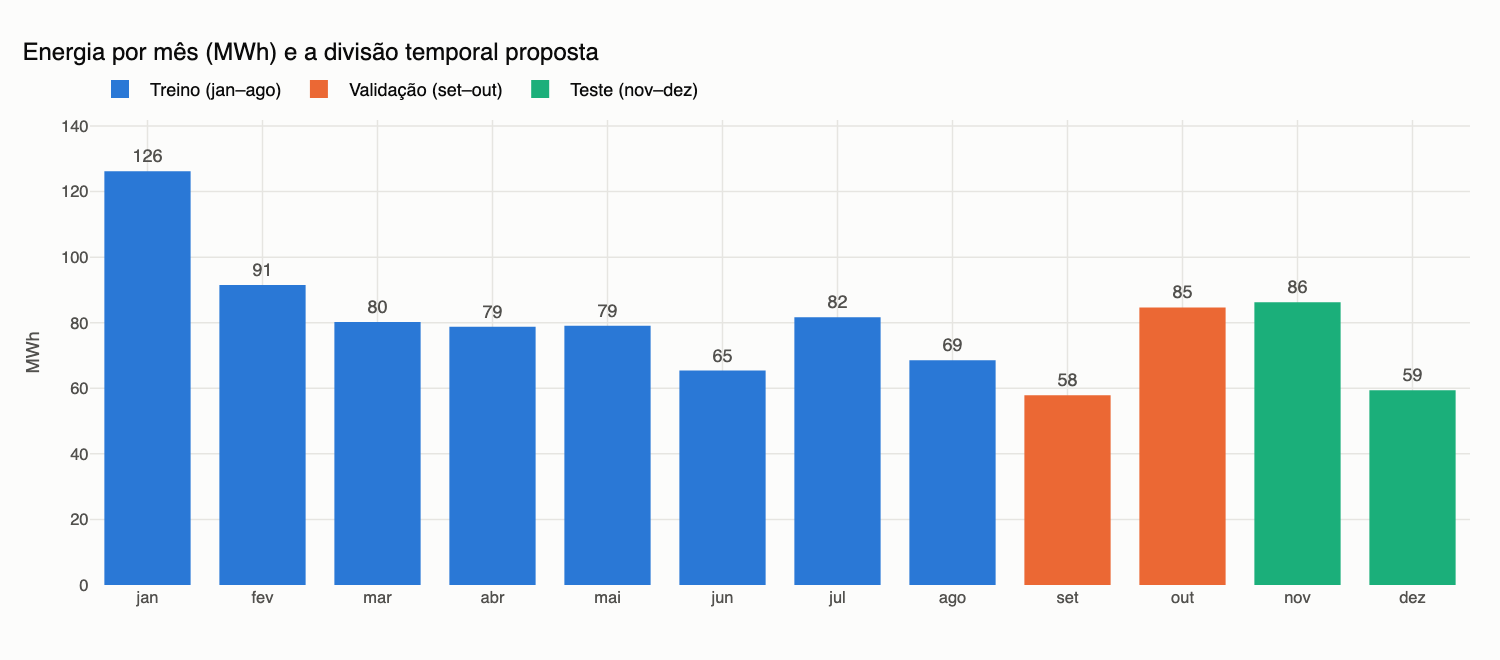

In [29]:
monthly = df.groupby(df["interval_start"].dt.month)["usage_kwh"].sum() / 1000
split = np.select(
    [monthly.index <= 8, monthly.index <= 10],
    ["Treino (jan–ago)", "Validação (set–out)"],
    "Teste (nov–dez)",
)
fig = go.Figure()
for i, label in enumerate(["Treino (jan–ago)", "Validação (set–out)", "Teste (nov–dez)"]):
    m = split == label
    fig.add_trace(
        go.Bar(
            x=[months[k - 1] for k in monthly.index[m]],
            y=monthly.values[m],
            name=label,
            marker=dict(color=CATEGORICAL[i]),
            text=[f"{v:.0f}" for v in monthly.values[m]],
            textposition="outside",
            textfont=dict(color=TEXT_SECONDARY),
        )
    )
fig.update_layout(
    title="Energia por mês (MWh) e a divisão temporal proposta",
    yaxis_title="MWh",
    bargap=0.25,
    height=440,
    hovermode="closest",
)
fig.show()

**Observações:**
- O consumo mensal varia bastante: janeiro tem cerca de 126 MWh, e setembro e dezembro menos de 60 MWh. A validação (setembro, com Chuseok) e o teste (dezembro, com fim de ano) incluem meses atípicos.
- Com **um único ano**, os meses de novembro e dezembro **nunca aparecem no treino**. Uma feature "mês" ensinaria ao modelo algo que ele não consegue aplicar no teste. **Recomendação: não usar o mês como feature numérica direta.** Se for necessário, usar algo como o regime tarifário de inverno ou verão, que aparece nos dois lados do split.
- O inverno (nov–fev) tem uma grade tarifária diferente. O treino contém janeiro e fevereiro, então esse regime não é totalmente novo no teste.

### Uma primeira medida de dificuldade

Na conversa anterior medimos, só em jan–ago, que repetir o valor de 1 hora atrás dá R² de cerca de 0,38, e repetir o valor de ontem no mesmo horário dá cerca de 0,21. A ACF acima explica por quê: a série muda de estado (opera ou para) de forma abrupta, e a persistência erra exatamente nessas transições. **O espaço para um modelo agregar valor existe, e está nas transições.** Os baselines formais serão construídos no Milestone 2.

## 12. Limitações do dataset

1. **Um único ano.** Não há como aprender sazonalidade anual nem validar em um segundo inverno.
2. **Uma única planta, de pequeno porte.** Os resultados não generalizam para aciarias ou outras unidades.
3. **Nenhuma variável de processo.** Não há produção (toneladas), equipamentos, turnos ou ordens de manutenção. Podemos descrever *quando* a planta consome, mas não *por quê*.
4. **Médias de 15 minutos.** Picos instantâneos de demanda não são observáveis.
5. **Calendário de operação desconhecido.** Feriados nacionais explicam só parte das paradas. Alguns domingos são trabalhados e alguns sábados não.
6. **Colunas redundantes.** CO2 e os dois fatores de potência são derivados do kWh e dos kVArh.
7. **Documentação da fonte com inconsistências.** A unidade de CO2 está errada (ppm) e `WeekStatus` aparece como 0/1, mas o arquivo tem texto. O problema dos rótulos da meia-noite não é mencionado em lugar nenhum.
8. **Disponibilidade da medição em tempo real** é uma premissa, não algo demonstrado.

## Resumo

- O arquivo é íntegro (sem nulos, duplicatas ou lacunas), mas **o rótulo das 00:00 está deslocado em um dia**. Corrigimos isso em código, com verificação e testes.
- **CO2 e fator de potência são reconstruções do alvo.** Usá-los no mesmo intervalo é a origem dos R² próximos de 1 em notebooks públicos.
- A planta tem um comportamento **liga/desliga** forte: repouso em mais da metade do tempo, jornada diurna com pausa ao meio-dia e paradas em fins de semana e feriados.
- **`Load_Type`** é uma grade tarifária, conhecida com antecedência, mais uma marcação de dias parados que acompanha a operação real. Fica fora das features.
- A memória da série está em **1h, 24h e principalmente 7 dias**. A dificuldade está nas transições de estado.

**Próximo passo (Milestone 2):** construir as features seguras, os baselines (persistência, mesmo horário de ontem, mesmo horário da semana passada) e os testes automatizados que garantem que nenhuma feature enxerga o futuro.